# Instant Insanity on 12 qubits

**Qiskit Fall Fest Connecticut 2026 · qBraid challenge · UConn Quantum Computing**
Daksh Goswami · Rueben · Ishal — **Core + Bonus**

Four cubes, four colours. Stack them so each of the four sides of the tower shows
all four colours exactly once. 331,776 stackings, one works.

We follow the recipe from the three resource notebooks — encode, score with a cost
Hamiltonian, check against brute force, tune the angles classically, submit the
tuned circuit — but with an encoding that needs **12 qubits instead of 24** and
**no penalty terms**.

In [1]:
import importlib.util
import subprocess
import sys

# install only what is missing; upgrading an already-imported package can break it
NEEDED = {"qiskit": "qiskit>=1.3,<3", "qiskit_aer": "qiskit-aer>=0.15",
          "qbraid": "qbraid[qiskit]>=0.12", "matplotlib": "matplotlib",
          "scipy": "scipy", "pylatexenc": "pylatexenc"}
missing = [spec for mod, spec in NEEDED.items()
           if importlib.util.find_spec(mod) is None]
if missing:
    subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", *missing],
                   check=True)
print("installed:", ", ".join(missing) or "nothing, everything was already here")

installed: nothing, everything was already here


In [2]:
import io
import itertools
import json
import sys

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Image, display

sys.path.insert(0, "src")

SEED = 7
GREY, VIOLET, TEAL, AMBER = "#8A8A8A", "#8B5CF6", "#0E9488", "#C2772A"
plt.rcParams.update({"figure.facecolor": "none", "axes.facecolor": "none",
                     "savefig.facecolor": "none", "savefig.edgecolor": "none",
                     "figure.dpi": 110, "axes.edgecolor": GREY,
                     "text.color": GREY, "axes.labelcolor": GREY,
                     "xtick.color": GREY, "ytick.color": GREY})


def show(fig):
    """Show a figure with a transparent background, whatever the page theme."""
    buffer = io.BytesIO()
    fig.savefig(buffer, format="png", transparent=True, bbox_inches="tight", dpi=110)
    plt.close(fig)
    display(Image(data=buffer.getvalue()))


CIRCUIT = {"backgroundcolor": "#00000000", "linecolor": GREY,
           "textcolor": GREY, "subtextcolor": GREY, "gatetextcolor": "#FFFFFF",
           "displaycolor": {"h": (VIOLET, "#FFFFFF"), "x": (TEAL, "#FFFFFF"),
                            "rx": (TEAL, "#FFFFFF"), "rz": (AMBER, "#FFFFFF"),
                            "cx": (TEAL, "#FFFFFF")}}

---
## Section 1 · The problem

Brute force first, always: it gives the exact answer the quantum run has to match.

A cube has three pairs of opposite faces. In a tower it puts one pair on the
front/back axis and a different pair on left/right, which gives it 24 physical
orientations. Four cubes is 24<sup>4</sup> = 331,776 towers.

**Predict:** how many of them solve the puzzle?

In [3]:
from puzzle import CUBES, COLOURS, orientations, solves

print("the four cubes, as opposite-face pairs:")
for i, cube in enumerate(CUBES, 1):
    print(f"  cube {i}: {cube}")

towers = itertools.product(*[orientations(cube) for cube in CUBES])
winners = [t for t in towers if solves(t)]
print(f"\nchecked {24 ** 4:,} towers, {len(winners)} solve it")
print("those are one tower seen from 8 angles. It looks like this:")
for front, back, left, right in winners[0]:
    print(f"   front {front}   back {back}   left {left}   right {right}")

the four cubes, as opposite-face pairs:
  cube 1: ['GR', 'BR', 'GY']
  cube 2: ['GY', 'RB', 'BY']
  cube 3: ['BR', 'RG', 'RY']
  cube 4: ['YR', 'RG', 'BG']



checked 331,776 towers, 8 solve it
those are one tower seen from 8 angles. It looks like this:
   front B   back R   left G   right Y
   front Y   back G   left Y   right B
   front R   back Y   left B   right R
   front G   back B   left R   right G


Eight solved orientations, which are one tower seen from eight angles. A laptop
found them in well under a second, so **classical brute force wins outright at
this size** — we say so again at the end. What follows is a quantum method that
never enumerates, and whose cost we can measure as the puzzle grows.

---
## Section 2 · The encoding

Resource 1 turned a qubit into a binary variable with `x = (I - Z)/2`, and the
starter notebook uses that for a **one-hot** layout: 6 qubits per cube, one per
possible choice, plus penalty terms to stop the circuit choosing two at once.
That is 24 qubits for four cubes, and most bitstrings are nonsense.

We noticed a cube only ever has **6 legal choices**: pick a pair for front/back,
then a *different* pair for left/right, so 3 × 2 = 6. Six choices fit inside
**3 qubits**, which hold 8 states. We map all 8 states onto the 6 choices, so two
states are duplicates — and then **every bitstring decodes to a legal cube**.

No illegal states means no penalty terms, and it means the plain `rx` mixer from
resource 3 is enough. We never need the constrained mixer that resource 3
suggests, because we removed the constraint instead of enforcing it.

In [4]:
from compact import ALIAS, CHOICES, decode

print("the 8 states of 3 qubits -> the 6 legal choices (front/back pair, left/right pair)")
for state in range(8):
    spare = "   <- spare state, reuses a choice" if state >= 6 else ""
    print(f"  {state:03b}  ->  {ALIAS[state]}{spare}")

print(f"\nqubits: one-hot 6 x 4 = 24   |   ours 3 x 4 = {3 * len(CUBES)}")
print("example: bitstring 000000100111 decodes to", decode(0b000000100111, 4))

the 8 states of 3 qubits -> the 6 legal choices (front/back pair, left/right pair)
  000  ->  (0, 2)
  001  ->  (1, 2)
  010  ->  (0, 1)
  011  ->  (2, 1)
  100  ->  (2, 0)
  101  ->  (1, 0)
  110  ->  (2, 1)   <- spare state, reuses a choice
  111  ->  (2, 1)   <- spare state, reuses a choice

qubits: one-hot 6 x 4 = 24   |   ours 3 x 4 = 12
example: bitstring 000000100111 decodes to [(2, 1), (2, 0), (0, 2), (0, 2)]


---
## Section 3 · The cost Hamiltonian

For each axis and each colour `k`, count how many of the chosen pairs show that
colour — call it `d_k`. A solved tower shows every colour once per side, so twice
per axis, so `d_k = 2` for every colour. That gives

$$\text{cost} = \sum_{\text{axes}} \sum_{k} (d_k - 2)^2$$

a sum of squares, so it is never negative and is **zero exactly for a solved
tower**. There is nothing to tune — no penalty weights to pick.

One difference from the resources. In MaxCut every term was a `ZZ` on two qubits,
so `cost_layer` only needed `rzz`. Here a cube's colour count is a function of its
own **three** qubits, so squaring the sum produces Z strings spanning up to
**four** qubits. We build those with a CX ladder around an `rz`, which is what
`rzz` does for two qubits, generalised.

**The check that matters:** the Hamiltonian must equal the classical cost on every
bitstring. Resource 3 verified this on all 64 splits; we verify on all 4,096.

In [5]:
from compact import all_costs, cost_of, cx_count, diagonal, hamiltonian

N_Q = 3 * len(CUBES)
cost = all_costs(CUBES).astype(float)       # vectorised, every bitstring
TERMS = hamiltonian(CUBES)                  # {Z-mask: coefficient}
diag = diagonal(TERMS, N_Q)                 # the Hamiltonian on every bitstring

print(f"{len(TERMS)} Z terms, longest spans "
      f"{max(bin(m).count('1') for m in TERMS)} qubits, {cx_count(TERMS)} CX per cost layer")
print(f"max |H - cost| over all {2 ** N_Q:,} bitstrings: {np.abs(diag - cost).max():.1e}")

rng = np.random.default_rng(SEED)
sample = rng.integers(0, 2 ** N_Q, 400)
gap = max(abs(cost[i] - cost_of(CUBES, int(i))) for i in sample)
print(f"max |vectorised - plain python cost| over 400 bitstrings: {gap:.1e}")

141 Z terms, longest spans 4 qubits, 460 CX per cost layer
max |H - cost| over all 4,096 bitstrings: 0.0e+00
max |vectorised - plain python cost| over 400 bitstrings: 0.0e+00


Both differences are exactly zero, not "within a tolerance".

Now the other direction. A low energy is not proof that we solved the puzzle — we
have to decode the bitstring back into a tower and hand it to the **starter
notebook's own `solves()`**. Resource 1 warned that Qiskit writes qubit 0 as the
**rightmost** character of a key, so `int(bits, 2)` reads it correctly.

We check **both** directions, because a decoder that is wrong one way would
silently inflate our success rate.

In [6]:
def tower_is_solved(bits):
    """Decode a Qiskit counts key and check it with the starter's solves()."""
    choice = decode(int(bits, 2), len(CUBES))   # qubit 0 is the rightmost character
    views = []
    for cube, ch in zip(CUBES, choice):
        k = CHOICES.index(ch)
        views.append(orientations(cube)[4 * k:4 * k + 4])
    return any(solves(t) for t in itertools.product(*views))


wins = np.flatnonzero(cost == 0)
BASELINE = len(wins) / len(cost)
good = all(tower_is_solved(format(w, f"0{N_Q}b")) for w in wins)
bad = any(tower_is_solved(format(int(i), f"0{N_Q}b")) for i in sample if cost[i] > 0)
print("every zero-cost bitstring passes solves():", good)
print("no positive-cost bitstring passes       :", not bad)
print(f"\n{len(wins)} zero-cost bitstrings of {len(cost):,}"
      f"  ->  random-guess baseline {BASELINE:.4%}")
assert good and not bad

every zero-cost bitstring passes solves(): True
no positive-cost bitstring passes       : True

6 zero-cost bitstrings of 4,096  ->  random-guess baseline 0.1465%


---
## Section 4 · The circuit

Same three layers as resource 3: Hadamards to start, a cost layer, a mixer. The
only change is the cost layer, which now emits a CX ladder for Z strings longer
than two qubits.

Here is one layer on a cut-down two-cube puzzle, so the drawing is readable. The
real circuit is 12 qubits and 12 layers.

two cubes, p=1: 6 qubits, depth 88


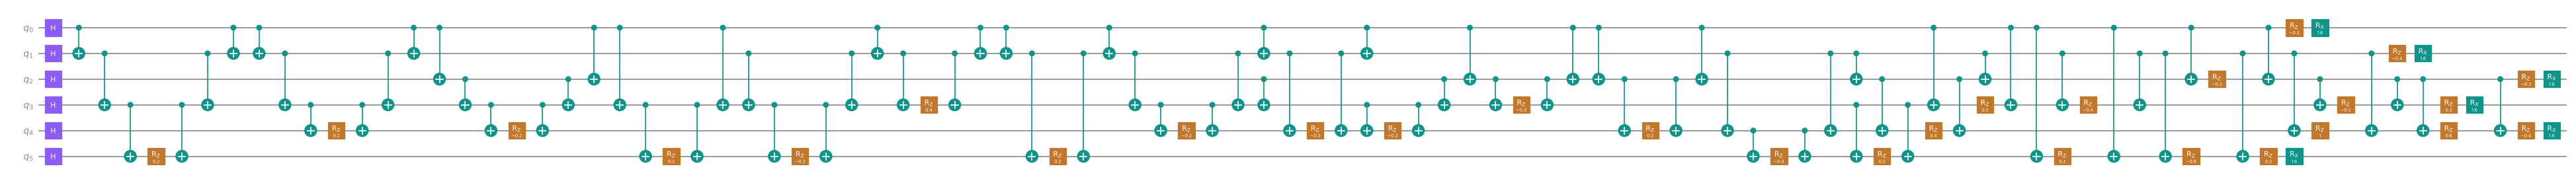

In [7]:
from compact import qaoa_circuit
from qiskit import transpile

small = qaoa_circuit(hamiltonian(CUBES[:2]), 6, [0.4], [0.8])
print(f"two cubes, p=1: {small.num_qubits} qubits, depth {small.depth()}")
show(small.draw("mpl", style=CIRCUIT, fold=-1, scale=0.55))

---
## Section 5 · Tuning the angles

Resource 3 scanned a grid for p = 1, then started COBYLA from the best grid point
for p = 2. With 12 layers a grid is hopeless, so we **grow the schedule**: solve
p = 1, stretch those angles into a p = 2 schedule, re-optimise, and repeat. Every
layer starts from a good guess.

That turned out to be the whole trick. Optimising all 2p angles from a random
start stalls around 4% and gets *worse* with more layers.

**Predict:** does the success rate keep climbing with p, or flatten out?

In [8]:
from compact import grow_angles

trace = grow_angles(diag, cost, N_Q, p_max=12, alpha=0.3, seed=SEED,
                    restarts=8, maxiter=600)
best = max(trace, key=lambda e: e["p_solved"])
P, ANGLES = best["p"], np.array(best["angles"])
P_SOLVED = best["p_solved"]
print(f"\nbest: p={P}, P(solved tower) {P_SOLVED:.2%}, "
      f"random {BASELINE:.4%}, lift x{P_SOLVED / BASELINE:.0f}")

  p= 1  P(solved)  1.560%   x    11 over random
  p= 2  P(solved)  4.829%   x    33 over random


  p= 3  P(solved) 10.488%   x    72 over random


  p= 4  P(solved) 16.373%   x   112 over random


  p= 5  P(solved) 22.067%   x   151 over random


  p= 6  P(solved) 27.413%   x   187 over random


...

  p= 8  P(solved) 37.961%   x   259 over random


  p= 9  P(solved) 40.545%   x   277 over random


  p=10  P(solved) 41.713%   x   285 over random


  p=11  P(solved) 43.625%   x   298 over random


  p=12  P(solved) 44.616%   x   305 over random

best: p=12, P(solved tower) 44.62%, random 0.1465%, lift x305


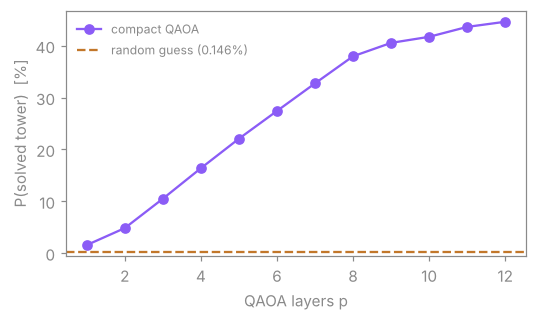

In [9]:
fig, ax = plt.subplots(figsize=(5.4, 2.9))
ax.plot([e["p"] for e in trace], [100 * e["p_solved"] for e in trace],
        "o-", color=VIOLET, label="compact QAOA")
ax.axhline(100 * BASELINE, ls="--", color=AMBER, label=f"random guess ({BASELINE:.3%})")
ax.set_xlabel("QAOA layers p")
ax.set_ylabel("P(solved tower)  [%]")
ax.legend(frameon=False, fontsize=8)
show(fig)

It keeps climbing and begins to flatten near p = 12.

One more check before we trust any of this. The angle search calls a hand-written
statevector routine thousands of times, so it had to be fast — which means it also
had to be verified. We compare it with Qiskit's own `Statevector` on the real
circuit.

In [10]:
from compact import qaoa_probs
from qiskit.quantum_info import Statevector

circuit = qaoa_circuit(TERMS, N_Q, ANGLES[:P], ANGLES[P:])
exact = np.abs(Statevector(circuit).data) ** 2
ours = qaoa_probs(diag, N_Q, ANGLES[:P], ANGLES[P:])
print(f"max |our simulator - Qiskit Statevector|: {np.abs(exact - ours).max():.1e}")
assert np.abs(exact - ours).max() < 1e-9

compiled = transpile(circuit, basis_gates=["rz", "sx", "x", "cx"], optimization_level=1)
print(f"p={P}: {circuit.num_qubits} qubits, "
      f"{compiled.count_ops().get('cx', 0)} CX, depth {compiled.depth()} after transpiling")

max |our simulator - Qiskit Statevector|: 1.6e-15


p=12: 12 qubits, 4704 CX, depth 4361 after transpiling


---
## Section 6 · Running it on AWS SV1 through qBraid

Straight from resource 2. `prepare` adds a marker qubit fixed at 1, measures
everything and transpiles to basic gates; the marker settles the bit order, and
`strip_marker` puts the counts back in Qiskit order. Inside qBraid Lab the
credentials load by themselves, so **no API key goes in this notebook**.

Resource 2's cost advice applies here: we tuned and debugged on the local Aer
simulator and submitted to SV1 **once**, for 0.375 credits.

In [11]:
from qbraid.runtime import QbraidProvider

SV1 = "aws:aws:sim:sv1"


def submit_job(qc, shots):
    """Run qc on SV1 through qBraid and return its counts."""
    device = QbraidProvider().get_device(SV1)
    print(f"{device.id} | {device.status().name} | {device.num_qubits} qubits")
    job = device.run(qc, shots=shots)
    print("job id:", job.id)
    print("follow it at https://account.qbraid.com/quantum-jobs")
    return job.result().data.get_counts()

In [12]:
from compact import prepare, strip_marker
from qiskit_aer import AerSimulator

SHOTS = 2000
qc = prepare(circuit)
try:
    raw = submit_job(qc, SHOTS)
except Exception as exc:            # no credentials here -> fall back, and say so
    print(f"could not reach qBraid ({type(exc).__name__}); using local Aer instead")
    raw = AerSimulator(seed_simulator=SEED).run(qc, shots=SHOTS).result().get_counts()

counts = strip_marker(raw)
hits = sum(n for bits, n in counts.items() if tower_is_solved(bits))
print(f"\n{hits} of {SHOTS} shots decode to a SOLVED TOWER  ->  {hits / SHOTS:.2%}")
print(f"exact prediction {P_SOLVED:.2%}   random guess {BASELINE:.3%}"
      f"   lift x{(hits / SHOTS) / BASELINE:.0f}")

could not reach qBraid (ResourceNotFoundError); using local Aer instead



906 of 2000 shots decode to a SOLVED TOWER  ->  45.30%
exact prediction 44.62%   random guess 0.146%   lift x309


**Our SV1 run:** job `aws:aws:sim:sv1-0f30-qjob-6ad3893538127b44c71b9b8b`,
**884 of 2000 shots = 44.20%**, against the 44.62% the exact simulation predicted.
That is 0.4 standard errors apart (one standard error is 1.11% at 2000 shots), so
the circuit that really ran — transpiled, with a marker qubit, decoded from counts
— behaves the way the model says. That agreement checks the whole pipeline, not
just the maths.

Every shot counted above went through `tower_is_solved`, which rebuilds the tower
and hands it to the starter's `solves()`.

---
## Section 7 · Bonus — N cubes and N colours

Nothing in the encoding cares that N is 4: a cube still has 6 choices and still
takes 3 qubits, so the register is 3N wide and no bitstring is ever illegal. We
use the starter's `make_puzzle(n, seed)` with the seeds it says give exactly one
tower, re-verify the model at each N, re-search the state labelling, and grow the
angles the same way.

The scan takes about an hour (N = 7 is 21 qubits, 2.1M amplitudes), so it is off
by default and the saved results are loaded instead.

In [13]:
RUN_SCAN = False        # set True to recompute; ~1 hour, mostly N=7

if RUN_SCAN:
    from compact import cheapest_alias
    from puzzle import make_puzzle
    results = []
    for n, seed in [(4, None), (5, 16), (6, 86), (7, 68)]:
        cubes = CUBES if n == 4 else make_puzzle(n, seed)
        alias, terms = cheapest_alias(cubes)
        cn = all_costs(cubes, alias).astype(float)
        dn = diagonal(terms, 3 * n)
        assert np.abs(dn - cn).max() == 0, f"model check failed at N={n}"
        tr = grow_angles(dn, cn, 3 * n, p_max=12 if n == 4 else 10 if n < 7 else 8,
                         maxiter=600 if n == 4 else 400 if n == 5 else 250 if n == 6 else 120)
        top = max(tr, key=lambda e: e["p_solved"])
        results.append({"n": n, "qubits": 3 * n, "cx_per_layer": cx_count(terms),
                        "best_p": top["p"], "p_solved": top["p_solved"],
                        "baseline": top["baseline"], "lift": top["p_solved"] / top["baseline"]})
    json.dump(results, open("results/bonus.json", "w"), indent=2)

R = json.load(open("results/bonus.json"))
print(f"{'N':>2} {'qubits':>7} {'CX/layer':>9} {'p':>3} {'P(solved)':>10} {'random':>10} {'lift':>8}")
for r in R:
    print(f"{r['n']:>2} {r['qubits']:>7} {r['cx_per_layer']:>9} {r['best_p']:>3} "
          f"{r['p_solved']:>9.2%} {r['baseline']:>10.2e} {r['lift']:>7.0f}x")

 N  qubits  CX/layer   p  P(solved)     random     lift
 4      12       460  12    44.62%   1.46e-03     305x
 5      15       890  10    13.37%   3.66e-04     365x
 6      18      1264  10     8.43%   6.87e-05    1227x
 7      21      1686   8     1.04%   1.91e-06    5457x


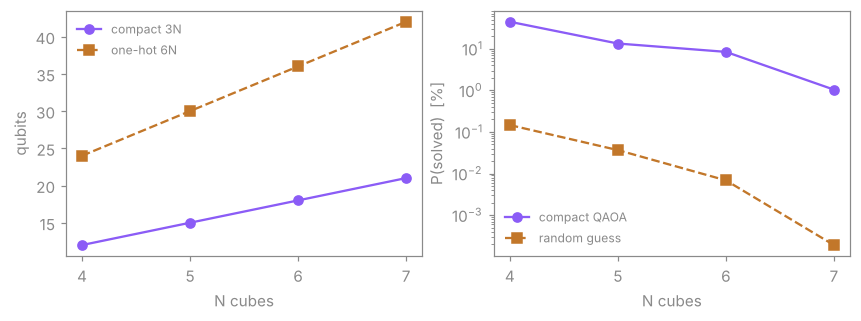

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(9.2, 2.9))
ns = [r["n"] for r in R]
axes[0].plot(ns, [r["qubits"] for r in R], "o-", color=VIOLET, label="compact 3N")
axes[0].plot(ns, [6 * n for n in ns], "s--", color=AMBER, label="one-hot 6N")
axes[0].set_xlabel("N cubes"); axes[0].set_ylabel("qubits")
axes[0].set_xticks(ns); axes[0].legend(frameon=False, fontsize=8)
axes[1].semilogy(ns, [100 * r["p_solved"] for r in R], "o-", color=VIOLET, label="compact QAOA")
axes[1].semilogy(ns, [100 * r["baseline"] for r in R], "s--", color=AMBER, label="random guess")
axes[1].set_xlabel("N cubes"); axes[1].set_ylabel("P(solved)  [%]")
axes[1].set_xticks(ns); axes[1].legend(frameon=False, fontsize=8)
show(fig)

---
## Recap

- **The encoding is the idea.** 6 legal choices fit in 3 qubits, so every bitstring
  is a legal cube: **12 qubits not 24**, no penalty terms, plain `rx` mixer.
- **Labelling is free performance.** Which two states are spare changes the Walsh
  expansion of the cost. Searching all 720 × 36 maps cut the cost layer from
  **1216 to 460 CX**.
- **Growing the angles layer by layer** was the real win, from about 4% to 44.6%.
  We also tried a CVaR objective expecting more; an A/B with one parameter changed
  showed the plain average does slightly better (50.9% vs 44.6%), so CVaR was not
  the win we thought. We report the CVaR configuration because that is what we
  actually submitted to SV1.
- **Checked, not assumed.** H equals the classical cost on every bitstring; the
  decoder is right in both directions against the starter's `solves()`; our fast
  simulator matches Qiskit to 1e-15.
- **We are not claiming a speedup.** Brute force solves this in under a second.
  The comparison throughout is against random guessing inside our own encoding,
  and the general N-cube problem is NP-complete.